# Time profiling of cloelib: where the time goes, and how it scales

What one full photometric 3x2pt evaluation costs in cloelib, broken into its parts, and how that cost depends on the problem size, the model and the number of CPUs. The comparisons with other codes are in the other folders of `../` (`euclid_dr3`, `euclid_dr1`, `speedcheck_reanalysis`). This notebook looks at cloelib alone, and collects what those comparisons revealed about it.

**Protocol** (as in the comparisons): one full 3x2pt evaluation from scratch, all $n_{\rm bin}(n_{\rm bin}+1)/2$ GG + $n_{\rm bin}^2$ GE + $n_{\rm bin}(n_{\rm bin}+1)/2$ EE spectra.
- **Timed:** fresh tracers and loop computers (FAST-PT), P(k) interpolators rebuilt, `AngularTwoPoint.get_Cl` for GG, GE and EE.
- **Not timed:** the CAMB runs behind `CAMBLinearPerturbations` / `CAMBNonLinearPerturbations`. Section 5 reports them separately.
- **Statistics:** median of 5 evaluations; the first call at each array shape is reported separately, because it includes JAX compilation.
- **Script:** `cloelib_benchmark.py`, run as a subprocess, so each CPU budget gets its own process (`taskset`).

**Models.**
- `linear`: polynomial linear galaxy bias + NLA.
- `pt`: one-loop galaxy bias (`PBJNonlinearBiasLoopComputer`) + TATT (`PBJTATTLoopComputer`).

Both use CAMB Mead2020 and the cosmology of the Euclid DR3 notebook.

**Reference set-up:** 13 bins (`nzTabSPV3.fits`), 32 $\ell$ (`geomspace(2, 2999, 32)`), $N_Z = 600$ redshift points for n(z), kernels and Limber. The CAMB P(k, z) grid has min($N_Z$, 250) points, because CAMB accepts at most 256 redshifts.

**Version:** cloelib `main` at `0966dfa` (2026-10-09, `tp_paths.CLOELIB['main-0966dfa']`), which includes the non-linear bias of PR #596.

**Running:** `run.sh` executes this notebook pinned to a CPU set (by default 96 CPUs of NUMA node 1 of `drontermeer`). Sections 1–3 and 5 run their subprocesses on 8 of those CPUs, section 4 on 1, 8 and all of them.

In [1]:
import json
import os
import subprocess
import sys
import time

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))   # time_profiling/, for tp_paths
import tp_paths as tp

RES, FIGURES = os.path.abspath('results'), os.path.abspath('figures')
os.makedirs(RES, exist_ok=True); os.makedirs(FIGURES, exist_ok=True)
CLOELIB = 'main-0966dfa'
tp.check(tp.CLOELIB[CLOELIB], tp.PY_CLOE_COSMOSIS, tp.NZ_SPV3, tp.NZ_DR1)
CPUS = sorted(os.sched_getaffinity(0))


def cpu_set(n):
    """The first n CPUs this kernel may use, as a taskset list."""
    return ','.join(map(str, CPUS[:n]))


BUDGETS = sorted({1, 8, len(CPUS)})
LAPTOP = CPUS[:8]                                              # sections 1-3, 5
mhz = []
for c in CPUS:
    try:
        mhz.append(int(open(f'/sys/devices/system/cpu/cpu{c}/cpufreq/scaling_cur_freq').read()) / 1e3)
    except OSError:
        pass
print(f'host {os.uname().nodename} | {len(CPUS)} CPUs available | budgets {BUDGETS} | load {os.getloadavg()[0]:.1f}'
      + (f' | clock min {min(mhz):.0f} MHz' if mhz else ''))


def run(name, args, n_cpu=8):
    """cloelib_benchmark.py on the first n_cpu CPUs; returns its JSON."""
    out = os.path.join(RES, f'{name}.json')
    env = {**os.environ, **{v: str(n_cpu) for v in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS')},
           'PYTHONWARNINGS': 'ignore'}
    cmd = ['taskset', '-c', cpu_set(n_cpu), str(tp.PY_CLOE_COSMOSIS), str(tp.CLOELIB_BENCHMARK),
           '--cloelib', CLOELIB, *args, '--out', out]
    t0, load0 = time.time(), os.getloadavg()[0]
    proc = subprocess.run(cmd, capture_output=True, text=True, env=env)
    with open(os.path.join(RES, f'{name}.log'), 'w') as f:
        f.write(proc.stdout + proc.stderr)
    assert proc.returncode == 0, proc.stderr[-3000:]
    lines = [l for l in proc.stdout.splitlines() if l.startswith(('cloelib ', 'profile'))]
    print('\n'.join(lines if len(lines) <= 6 else lines[:2] + ['   ...'] + lines[-3:]))
    print(f'   [{name}: {time.time() - t0:.0f} s, {n_cpu} CPUs, load {load0:.1f} -> {os.getloadavg()[0]:.1f}]')
    with open(out) as f:
        return json.load(f)


MODELS = ('linear', 'pt')
REF = dict(n_z=600, nell=32)

host drontermeer.strw.leidenuniv.nl | 96 CPUs available | budgets [1, 8, 96] | load 14.2 | clock min 2750 MHz


## 1. Where the time goes at the reference set-up
13 bins, 32 $\ell$, $N_Z = 600$, 8 CPUs. Per-stage medians (`--breakdown`, each stage synchronised with `jax.block_until_ready`), and a cProfile of one evaluation (`--profile`).
- **Self time by library:** FAST-PT, JAX/XLA dispatch, CAMB library calls (distances, interpolators; not Boltzmann runs), cloelib's own Python, NumPy/SciPy.
- **Eager JAX dispatches:** the number of JAX primitives executed one at a time outside a `jax.jit` (`jax/_src/dispatch.py:apply_primitive`). Each costs tens of microseconds regardless of array size.

In [2]:
ref = {m: run(f'reference_{m}', ['--model', m, '--n-z', str(REF['n_z']), '--nell', str(REF['nell']),
                                  '--repeat', '5', '--breakdown', '--profile']) for m in MODELS}
for m in MODELS:
    r = ref[m]
    b = r['breakdown'][str(REF['n_z'])][str(REF['nell'])]
    t = r['from_scratch'][str(REF['n_z'])][str(REF['nell'])]
    p = r['profile']
    print(f'\nmodel {m}: one evaluation {t:.3f} s (median of 5) | first call {r["first_call"][str(REF["n_z"])][str(REF["nell"])]:.2f} s')
    print('  stages (median): ' + ', '.join(f'{k} {v:.3f} s' for k, v in b.items()) + f'  (sum {sum(b.values()):.3f} s)')
    print(f'  cProfile of one evaluation ({p["total_s"]:.3f} s with profiling overhead), self time: '
          + ', '.join(f'{k} {v:.3f} s ({v / p["total_s"] * 100:.0f}%)' for k, v in sorted(p['groups_s'].items(), key=lambda x: -x[1])))
    print(f'  eager JAX primitive dispatches: {p["eager_jax_dispatches"]}')

cloelib linear 13 bins N_Z=  600 (P(k,z) 250) n_ell=   32 | from scratch   0.131 s | first call   2.21 s | 351 spectra
profile (N_Z=600, n_ell=32, 0.206 s): JAX/XLA 0.136s, NumPy/SciPy 0.029s, builtins / C 0.026s, CAMB library calls 0.006s, cloelib 0.005s, other Python 0.004s | 2041 eager JAX dispatches
   [reference_linear: 12 s, 8 CPUs, load 14.2 -> 14.6]


cloelib pt     13 bins N_Z=  600 (P(k,z) 250) n_ell=   32 | from scratch   0.394 s | first call   4.87 s | 351 spectra
profile (N_Z=600, n_ell=32, 0.511 s): JAX/XLA 0.222s, CAMB library calls 0.095s, FAST-PT 0.066s, builtins / C 0.059s, NumPy/SciPy 0.051s, cloelib 0.011s, other Python 0.007s | 2175 eager JAX dispatches
   [reference_pt: 16 s, 8 CPUs, load 14.6 -> 15.5]

model linear: one evaluation 0.131 s (median of 5) | first call 2.21 s
  stages (median): tracers 0.002 s, get_Cl GG 0.019 s, get_Cl GE 0.046 s, get_Cl EE 0.064 s  (sum 0.130 s)
  cProfile of one evaluation (0.206 s with profiling overhead), self time: JAX/XLA 0.136 s (66%), NumPy/SciPy 0.029 s (14%), builtins / C 0.026 s (13%), CAMB library calls 0.006 s (3%), cloelib 0.005 s (2%), other Python 0.004 s (2%)
  eager JAX primitive dispatches: 2041

model pt: one evaluation 0.394 s (median of 5) | first call 4.87 s
  stages (median): tracers 0.001 s, get_Cl GG 0.147 s, get_Cl GE 0.162 s, get_Cl EE 0.079 s  (sum 0.389 s)
 

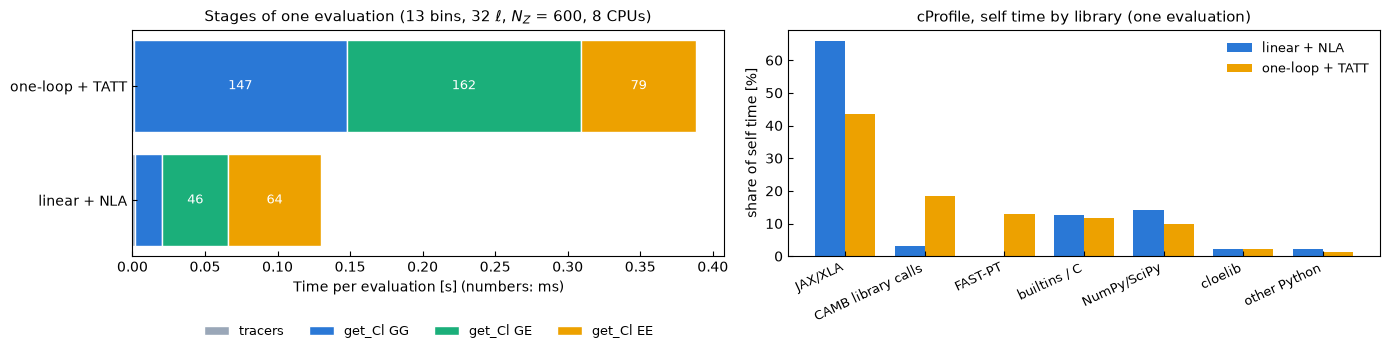

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
STAGE_COL = {'tracers': '#9aa7b8', 'get_Cl GG': '#2a78d6', 'get_Cl GE': '#1baf7a', 'get_Cl EE': '#eda100'}
ax = axes[0]
for i, m in enumerate(MODELS):
    left = 0.0
    for k, v in ref[m]['breakdown'][str(REF['n_z'])][str(REF['nell'])].items():
        ax.barh(i, v, left=left, color=STAGE_COL[k], edgecolor='white', label=k if i == 0 else None)
        if v > 0.02:
            ax.text(left + v / 2, i, f'{v * 1e3:.0f}', ha='center', va='center', fontsize=9, color='white')
        left += v
ax.set_yticks(range(len(MODELS))); ax.set_yticklabels(['linear + NLA', 'one-loop + TATT'])
ax.set_xlabel('Time per evaluation [s] (numbers: ms)')
ax.set_title('Stages of one evaluation (13 bins, 32 $\\ell$, $N_Z$ = 600, 8 CPUs)', fontsize=11)
ax.legend(frameon=False, fontsize=9, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.25))
ax = axes[1]
groups = sorted({g for m in MODELS for g in ref[m]['profile']['groups_s']},
                key=lambda g: -max(ref[m]['profile']['groups_s'].get(g, 0) for m in MODELS))
x = np.arange(len(groups))
for j, m in enumerate(MODELS):
    p = ref[m]['profile']
    ax.bar(x + (j - 0.5) * 0.38, [p['groups_s'].get(g, 0) / p['total_s'] * 100 for g in groups], width=0.38,
           color=['#2a78d6', '#eda100'][j], label=['linear + NLA', 'one-loop + TATT'][j])
ax.set_xticks(x); ax.set_xticklabels(groups, rotation=25, ha='right', fontsize=9)
ax.set_ylabel('share of self time [%]')
ax.set_title('cProfile, self time by library (one evaluation)', fontsize=11)
ax.legend(frameon=False, fontsize=9)
for a in axes:
    a.tick_params(direction='in')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, 'cloelib_where_the_time_goes.png'), dpi=150, bbox_inches='tight')
plt.show()

**Result: at the analysis set-up, cloelib's time is mostly JAX dispatch, and three Limber calls.**

| | linear + NLA | one-loop + TATT |
|---|---|---|
| one evaluation (median of 5) | **0.13 s** | **0.39 s** |
| tracers, incl. loop computers | 2 ms | 1 ms |
| `get_Cl` GG / GE / EE | 19 / 46 / 64 ms | 147 / 162 / 79 ms |
| eager JAX dispatches | 2,041 | 2,175 |
| largest share of self time | JAX/XLA 66% | JAX/XLA 43%, CAMB library calls 19%, FAST-PT 13% |

- **Tracer construction is negligible.** The work happens inside the three `get_Cl` calls: kernels, the P(k) "bank" of every contribution, and the Limber sum.
- **The linear model is dispatch-bound.** About 2,000 JAX primitives run one at a time outside `jax.jit`. That fixed cost is about 0.1 s however small the problem, and it is why the July 2026 speedcheck's tiny set-up favoured former CLOE.
- **With perturbation theory, GG and GE dominate**, because the one-loop bias terms are evaluated for each pair of terms. The CAMB library calls (19%) are P(k) and growth interpolators queried on the k and z grids; FAST-PT itself takes 13%.

## 2. Scaling with the problem size
8 CPUs. Each point is a new array shape: the median of 5 evaluations, plus the first call, which includes compilation.
- $N_Z \in \{100, 250, 600, 1000\}$ at $n_\ell = 32$;
- $n_\ell \in \{32, 100, 1000, 3000\}$ at $N_Z = 600$;
- 6 bins (DR1-like) and 13 bins (DR3-like).

In [4]:
NZS, NELLS = [100, 250, 600, 1000], [32, 100, 1000, 3000]
scal = {}
for m in MODELS:
    for nb in (6, 13):
        scal[m, nb, 'nz'] = run(f'scaling_nz_{m}_{nb}bins', ['--model', m, '--n-bins', str(nb), '--nell', '32',
                                                            '--n-z', *map(str, NZS), '--repeat', '5'])
        scal[m, nb, 'nell'] = run(f'scaling_nell_{m}_{nb}bins', ['--model', m, '--n-bins', str(nb), '--n-z', '600',
                                                                '--nell', *map(str, NELLS), '--repeat', '5'])

cloelib linear 6 bins N_Z=  100 (P(k,z) 100) n_ell=   32 | from scratch   0.042 s | first call   1.94 s | 78 spectra
cloelib linear 6 bins N_Z=  250 (P(k,z) 250) n_ell=   32 | from scratch   0.062 s | first call   1.91 s | 78 spectra
cloelib linear 6 bins N_Z=  600 (P(k,z) 250) n_ell=   32 | from scratch   0.072 s | first call   1.95 s | 78 spectra
cloelib linear 6 bins N_Z= 1000 (P(k,z) 250) n_ell=   32 | from scratch   0.123 s | first call   2.01 s | 78 spectra
   [scaling_nz_linear_6bins: 34 s, 8 CPUs, load 15.5 -> 16.8]


cloelib linear 6 bins N_Z=  600 (P(k,z) 250) n_ell=   32 | from scratch   0.076 s | first call   2.03 s | 78 spectra
cloelib linear 6 bins N_Z=  600 (P(k,z) 250) n_ell=  100 | from scratch   0.089 s | first call   1.88 s | 78 spectra
cloelib linear 6 bins N_Z=  600 (P(k,z) 250) n_ell= 1000 | from scratch   0.258 s | first call   2.10 s | 78 spectra
cloelib linear 6 bins N_Z=  600 (P(k,z) 250) n_ell= 3000 | from scratch   0.588 s | first call   2.11 s | 78 spectra
   [scaling_nell_linear_6bins: 22 s, 8 CPUs, load 16.8 -> 16.1]


cloelib linear 13 bins N_Z=  100 (P(k,z) 100) n_ell=   32 | from scratch   0.097 s | first call   2.09 s | 351 spectra
cloelib linear 13 bins N_Z=  250 (P(k,z) 250) n_ell=   32 | from scratch   0.160 s | first call   2.13 s | 351 spectra
cloelib linear 13 bins N_Z=  600 (P(k,z) 250) n_ell=   32 | from scratch   0.223 s | first call   2.13 s | 351 spectra
cloelib linear 13 bins N_Z= 1000 (P(k,z) 250) n_ell=   32 | from scratch   0.171 s | first call   2.24 s | 351 spectra
   [scaling_nz_linear_13bins: 36 s, 8 CPUs, load 16.1 -> 15.7]


cloelib linear 13 bins N_Z=  600 (P(k,z) 250) n_ell=   32 | from scratch   0.154 s | first call   2.27 s | 351 spectra
cloelib linear 13 bins N_Z=  600 (P(k,z) 250) n_ell=  100 | from scratch   0.141 s | first call   2.06 s | 351 spectra
cloelib linear 13 bins N_Z=  600 (P(k,z) 250) n_ell= 1000 | from scratch   0.303 s | first call   2.25 s | 351 spectra
cloelib linear 13 bins N_Z=  600 (P(k,z) 250) n_ell= 3000 | from scratch   0.542 s | first call   2.33 s | 351 spectra
   [scaling_nell_linear_13bins: 21 s, 8 CPUs, load 15.7 -> 15.6]


cloelib pt     6 bins N_Z=  100 (P(k,z) 100) n_ell=   32 | from scratch   0.187 s | first call   4.20 s | 78 spectra
cloelib pt     6 bins N_Z=  250 (P(k,z) 250) n_ell=   32 | from scratch   0.255 s | first call   4.22 s | 78 spectra
cloelib pt     6 bins N_Z=  600 (P(k,z) 250) n_ell=   32 | from scratch   0.337 s | first call   4.24 s | 78 spectra
cloelib pt     6 bins N_Z= 1000 (P(k,z) 250) n_ell=   32 | from scratch   0.415 s | first call   4.23 s | 78 spectra
   [scaling_nz_pt_6bins: 46 s, 8 CPUs, load 15.6 -> 15.2]


cloelib pt     6 bins N_Z=  600 (P(k,z) 250) n_ell=   32 | from scratch   0.335 s | first call   4.49 s | 78 spectra
cloelib pt     6 bins N_Z=  600 (P(k,z) 250) n_ell=  100 | from scratch   0.480 s | first call   4.28 s | 78 spectra
cloelib pt     6 bins N_Z=  600 (P(k,z) 250) n_ell= 1000 | from scratch   2.225 s | first call   5.61 s | 78 spectra
cloelib pt     6 bins N_Z=  600 (P(k,z) 250) n_ell= 3000 | from scratch   5.959 s | first call   8.69 s | 78 spectra
   [scaling_nell_pt_6bins: 75 s, 8 CPUs, load 15.2 -> 13.4]


cloelib pt     13 bins N_Z=  100 (P(k,z) 100) n_ell=   32 | from scratch   0.228 s | first call   4.47 s | 351 spectra
cloelib pt     13 bins N_Z=  250 (P(k,z) 250) n_ell=   32 | from scratch   0.323 s | first call   4.24 s | 351 spectra
cloelib pt     13 bins N_Z=  600 (P(k,z) 250) n_ell=   32 | from scratch   0.396 s | first call   4.29 s | 351 spectra
cloelib pt     13 bins N_Z= 1000 (P(k,z) 250) n_ell=   32 | from scratch   0.441 s | first call   4.37 s | 351 spectra
   [scaling_nz_pt_13bins: 47 s, 8 CPUs, load 13.4 -> 12.9]


cloelib pt     13 bins N_Z=  600 (P(k,z) 250) n_ell=   32 | from scratch   0.378 s | first call   4.80 s | 351 spectra
cloelib pt     13 bins N_Z=  600 (P(k,z) 250) n_ell=  100 | from scratch   0.548 s | first call   4.48 s | 351 spectra
cloelib pt     13 bins N_Z=  600 (P(k,z) 250) n_ell= 1000 | from scratch   2.334 s | first call   5.90 s | 351 spectra
cloelib pt     13 bins N_Z=  600 (P(k,z) 250) n_ell= 3000 | from scratch   6.017 s | first call   8.98 s | 351 spectra
   [scaling_nell_pt_13bins: 77 s, 8 CPUs, load 12.9 -> 11.2]


Median time per evaluation [s] (first call incl. compilation in brackets), 8 CPUs

N_Z (n_ell = 32)                  100              250              600             1000
  linear  6 bins       0.042 (  1.9)   0.062 (  1.9)   0.072 (  1.9)   0.123 (  2.0)
  linear 13 bins       0.097 (  2.1)   0.160 (  2.1)   0.223 (  2.1)   0.171 (  2.2)
  pt      6 bins       0.187 (  4.2)   0.255 (  4.2)   0.337 (  4.2)   0.415 (  4.2)
  pt     13 bins       0.228 (  4.5)   0.323 (  4.2)   0.396 (  4.3)   0.441 (  4.4)

n_ell (N_Z = 600)                  32              100             1000             3000
  linear  6 bins       0.076 (  2.0)   0.089 (  1.9)   0.258 (  2.1)   0.588 (  2.1)
  linear 13 bins       0.154 (  2.3)   0.141 (  2.1)   0.303 (  2.2)   0.542 (  2.3)
  pt      6 bins       0.335 (  4.5)   0.480 (  4.3)   2.225 (  5.6)   5.959 (  8.7)
  pt     13 bins       0.378 (  4.8)   0.548 (  4.5)   2.334 (  5.9)   6.017 (  9.0)



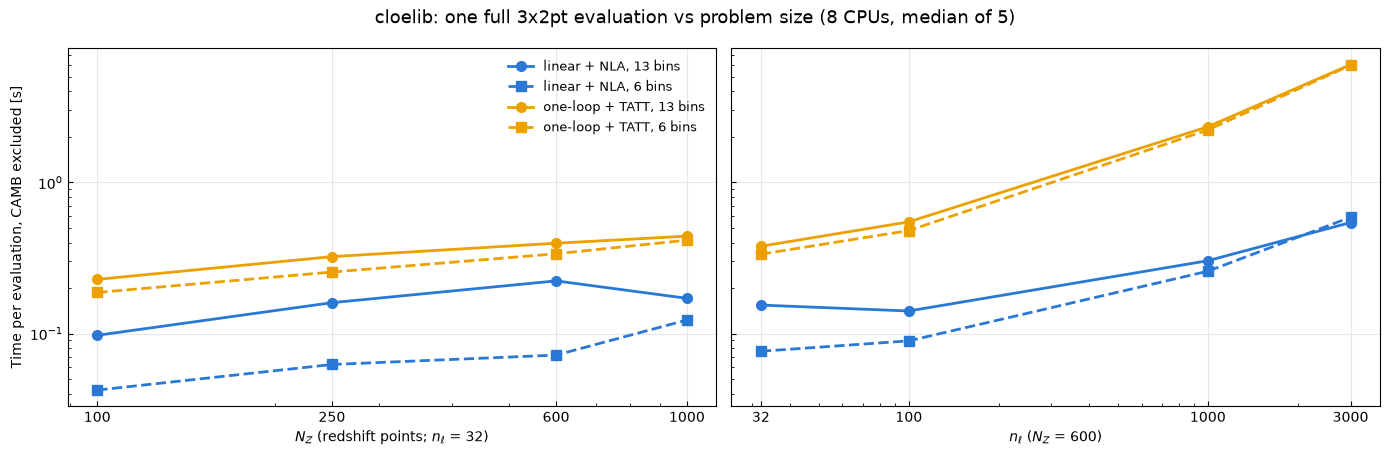

In [5]:
def series(m, nb, kind, key='from_scratch'):
    r = scal[m, nb, kind][key]
    return ([r[str(n)]['32'] for n in NZS] if kind == 'nz' else [r['600'][str(n)] for n in NELLS])


print('Median time per evaluation [s] (first call incl. compilation in brackets), 8 CPUs\n')
for kind, grid, label in (('nz', NZS, 'N_Z (n_ell = 32)'), ('nell', NELLS, 'n_ell (N_Z = 600)')):
    print(f'{label:20s} ' + ' '.join(f'{g:>16d}' for g in grid))
    for m in MODELS:
        for nb in (6, 13):
            med, first = series(m, nb, kind), series(m, nb, kind, 'first_call')
            print(f'  {m:6s} {nb:2d} bins     ' + ' '.join(f'{a:7.3f} ({b:5.1f})' for a, b in zip(med, first)))
    print()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, kind, grid, xl in ((axes[0], 'nz', NZS, '$N_Z$ (redshift points; $n_\\ell$ = 32)'),
                           (axes[1], 'nell', NELLS, '$n_\\ell$ ($N_Z$ = 600)')):
    for m, col in zip(MODELS, ('#2a78d6', '#eda100')):
        for nb, ls, mk in ((13, '-', 'o'), (6, '--', 's')):
            ax.plot(grid, series(m, nb, kind), ls=ls, marker=mk, color=col, lw=2, ms=7,
                    label=f'{"linear + NLA" if m == "linear" else "one-loop + TATT"}, {nb} bins')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xticks(grid); ax.set_xticklabels(grid)
    ax.set_xlabel(xl)
    ax.grid(True, which='major', color='0.9')
    ax.tick_params(direction='in', which='both')
axes[0].set_ylabel('Time per evaluation, CAMB excluded [s]')
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle('cloelib: one full 3x2pt evaluation vs problem size (8 CPUs, median of 5)', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, 'cloelib_scaling.png'), dpi=150, bbox_inches='tight')
plt.show()

**Result: cost grows gently with $N_Z$ and steeply with $n_\ell$ in the one-loop model, almost independently of the number of bins.**
- **$N_Z$ from 100 to 1000** ($n_\ell = 32$): linear + NLA 0.04–0.12 s (6 bins) and 0.10–0.22 s (13 bins); one-loop + TATT 0.19–0.42 s (6 bins) and 0.23–0.44 s (13 bins). Ten times more redshift points costs at most about 2x.
- **$n_\ell$ from 32 to 3000** ($N_Z = 600$): linear + NLA rises from 0.08–0.15 s to 0.54–0.59 s. One-loop + TATT rises from 0.34–0.38 s to **6.0 s**.
- **6 and 13 bins cost the same at large $n_\ell$** (2.2 vs 2.3 s at 1000, 6.0 vs 6.0 s at 3000), although 13 bins have 4.5x more spectra. The expensive step is not per spectrum. It is building the one-loop P(k, z) bank at every Limber point $k = (\ell + 1/2)/\chi(z)$, i.e. on $n_\ell \times N_Z$ points, once per term. That is the first place to optimise for high-$\ell$ analyses.
- **Noise:** medians below 0.3 s scatter by up to ±30% between runs. For example, linear + NLA, 13 bins at $N_Z = 600$ took 0.22 s in one run and 0.15 s in another, so the dip at $N_Z = 1000$ is noise.

## 3. JIT compilation
The first call at each array shape compiles every jitted function for that shape. Every change of $n_\ell$, $N_Z$ or the number of bins is a new shape. The table is the first call minus the median, i.e. the one-off compilation, from the runs of section 2.

In [6]:
print('One-off compilation per array shape [s] (first call - median), 8 CPUs\n')
for kind, grid, label in (('nz', NZS, 'N_Z (n_ell = 32)'), ('nell', NELLS, 'n_ell (N_Z = 600)')):
    print(f'{label:20s} ' + ' '.join(f'{g:>7d}' for g in grid))
    for m in MODELS:
        for nb in (6, 13):
            jit = [f - t for f, t in zip(series(m, nb, kind, 'first_call'), series(m, nb, kind))]
            print(f'  {m:6s} {nb:2d} bins     ' + ' '.join(f'{j:7.2f}' for j in jit))
    print()

One-off compilation per array shape [s] (first call - median), 8 CPUs

N_Z (n_ell = 32)         100     250     600    1000
  linear  6 bins        1.90    1.85    1.88    1.89
  linear 13 bins        1.99    1.97    1.90    2.06
  pt      6 bins        4.01    3.97    3.91    3.81
  pt     13 bins        4.24    3.92    3.89    3.93

n_ell (N_Z = 600)         32     100    1000    3000
  linear  6 bins        1.96    1.79    1.84    1.52
  linear 13 bins        2.12    1.92    1.94    1.79
  pt      6 bins        4.15    3.80    3.39    2.73
  pt     13 bins        4.42    3.94    3.57    2.96



**Result: compilation costs about 2 s (linear + NLA) or 4 s (one-loop + TATT) per array shape on 8 CPUs, whatever the size.**
- It does not grow with $N_Z$, $n_\ell$ or the number of bins: the traced program has the same structure, only its array shapes change.
- On 1 CPU it is 4 s and 11 s (section 4).
- It is paid again for every new combination of $N_Z$, $n_\ell$ and bins, and in every new process. A chain pays it once per worker. A script that evaluates a single point pays it every time.

## 4. CPU budget
The reference set-up and $n_\ell = 3000$, on 1, 8 and all CPUs of this kernel. Each run sets `taskset` and `OMP/MKL/OPENBLAS_NUM_THREADS`; JAX/XLA sizes its thread pool from the affinity mask.

In [7]:
cpu = {}
for n in BUDGETS:
    for m in MODELS:
        cpu[m, n] = run(f'cpus_{m}_{n}cpu', ['--model', m, '--n-z', '600', '--nell', '32', '3000', '--repeat', '5'],
                        n_cpu=n)
print(f'\nMedian time per evaluation [s], 13 bins, N_Z = 600\n')
print(f'{"":24s}' + ''.join(f'{f"{n} CPU" + ("s" if n > 1 else ""):>12s}' for n in BUDGETS))
for m in MODELS:
    for nell in (32, 3000):
        print(f'  {m:6s} n_ell = {nell:5d}   ' + ''.join(f'{cpu[m, n]["from_scratch"]["600"][str(nell)]:12.3f}' for n in BUDGETS))

cloelib linear 13 bins N_Z=  600 (P(k,z) 250) n_ell=   32 | from scratch   0.136 s | first call   4.13 s | 351 spectra
cloelib linear 13 bins N_Z=  600 (P(k,z) 250) n_ell= 3000 | from scratch   0.791 s | first call   4.59 s | 351 spectra
   [cpus_linear_1cpu: 45 s, 1 CPUs, load 11.2 -> 9.7]


cloelib pt     13 bins N_Z=  600 (P(k,z) 250) n_ell=   32 | from scratch   0.434 s | first call  11.23 s | 351 spectra
cloelib pt     13 bins N_Z=  600 (P(k,z) 250) n_ell= 3000 | from scratch  13.312 s | first call  23.84 s | 351 spectra
   [cpus_pt_1cpu: 134 s, 1 CPUs, load 9.7 -> 8.1]


cloelib linear 13 bins N_Z=  600 (P(k,z) 250) n_ell=   32 | from scratch   0.127 s | first call   2.22 s | 351 spectra
cloelib linear 13 bins N_Z=  600 (P(k,z) 250) n_ell= 3000 | from scratch   0.561 s | first call   2.31 s | 351 spectra
   [cpus_linear_8cpu: 18 s, 8 CPUs, load 8.1 -> 8.6]


cloelib pt     13 bins N_Z=  600 (P(k,z) 250) n_ell=   32 | from scratch   0.381 s | first call   4.94 s | 351 spectra
cloelib pt     13 bins N_Z=  600 (P(k,z) 250) n_ell= 3000 | from scratch   6.068 s | first call   8.96 s | 351 spectra
   [cpus_pt_8cpu: 53 s, 8 CPUs, load 8.6 -> 9.1]


cloelib linear 13 bins N_Z=  600 (P(k,z) 250) n_ell=   32 | from scratch   0.296 s | first call   2.38 s | 351 spectra
cloelib linear 13 bins N_Z=  600 (P(k,z) 250) n_ell= 3000 | from scratch   0.659 s | first call   2.41 s | 351 spectra
   [cpus_linear_96cpu: 30 s, 96 CPUs, load 9.1 -> 39.5]


cloelib pt     13 bins N_Z=  600 (P(k,z) 250) n_ell=   32 | from scratch   0.525 s | first call   4.64 s | 351 spectra
cloelib pt     13 bins N_Z=  600 (P(k,z) 250) n_ell= 3000 | from scratch   4.698 s | first call   7.44 s | 351 spectra
   [cpus_pt_96cpu: 46 s, 96 CPUs, load 39.5 -> 41.4]

Median time per evaluation [s], 13 bins, N_Z = 600

                               1 CPU      8 CPUs     96 CPUs
  linear n_ell =    32          0.136       0.127       0.296
  linear n_ell =  3000          0.791       0.561       0.659
  pt     n_ell =    32          0.434       0.381       0.525
  pt     n_ell =  3000         13.312       6.068       4.698


**Result: more CPUs help cloelib only when the problem is large.**

| 13 bins, $N_Z = 600$ | 1 CPU | 8 CPUs | 96 CPUs |
|---|---|---|---|
| linear + NLA, $n_\ell = 32$ | 0.14 s | 0.13 s | 0.30 s |
| linear + NLA, $n_\ell = 3000$ | 0.79 s | 0.56 s | 0.66 s |
| one-loop + TATT, $n_\ell = 32$ | 0.43 s | 0.38 s | 0.53 s |
| one-loop + TATT, $n_\ell = 3000$ | 13.3 s | 6.1 s | 4.7 s |

- **At the analysis set-up ($n_\ell = 32$), 1 and 8 CPUs give the same time, and 96 CPUs are slower.** XLA's thread pool and CAMB's OpenMP threads cost more than they save on arrays this small.
- **Only the large one-loop problem scales:** 2.2x from 1 to 8 CPUs, and 1.3x more to 96.
- For sampling, give each worker a few CPUs and run many workers, rather than one worker on a whole node.
- **Caveat for the 96-CPU column:** the load average rose from about 9 to 40 during those runs. Part of that is the runs' own threads, but another user was also active, so treat that column as an upper bound.

## 5. CAMB, outside the timed evaluation
The protocol excludes the CAMB runs behind `CAMBNonLinearPerturbations` + `CAMBLinearPerturbations`, but a sampler pays them at every new cosmology. `cloelib_benchmark.py` records their construction time once per grid (8 CPUs, section 2 runs).

In [8]:
print('CAMB construction, CAMBNonLinearPerturbations (Mead2020) + CAMBLinearPerturbations [s], 8 CPUs')
for n in NZS:
    g = scal['pt', 13, 'nz']['grids'][str(n)]
    print(f'  N_Z = {n:5d}: P(k, z) grid {g["pk_z"]:3d} redshifts, {g["k"]} k-values: {g["camb_s"]:.2f} s')

CAMB construction, CAMBNonLinearPerturbations (Mead2020) + CAMBLinearPerturbations [s], 8 CPUs
  N_Z =   100: P(k, z) grid 100 redshifts, 211 k-values: 4.86 s
  N_Z =   250: P(k, z) grid 250 redshifts, 211 k-values: 5.08 s
  N_Z =   600: P(k, z) grid 250 redshifts, 211 k-values: 5.14 s
  N_Z =  1000: P(k, z) grid 250 redshifts, 211 k-values: 5.29 s


**Result: CAMB, outside the timed evaluation, costs about 5 s per cosmology on 8 CPUs: 10–40 times the C$_\ell$ evaluation at the analysis set-up.**
- It barely depends on $N_Z$ (4.9–5.3 s for 100–250 P(k, z) redshifts).
- cloelib runs two separate CAMB calculations, a non-linear one to kmax = 500 and a linear one to kmax = 300 (`CAMBNonLinearPerturbations` + `CAMBLinearPerturbations`).
- In a chain this dominates every likelihood evaluation. A single CAMB call shared by both objects, or an emulator (`HMcode2020Emu`), would matter more than any C$_\ell$ optimisation.

## 6. Summary and known performance issues
At the analysis set-up (13 bins, 32 $\ell$, $N_Z = 600$, 8 CPUs), cloelib evaluates a full 3x2pt in **0.13 s** with linear bias + NLA and **0.39 s** with one-loop bias + TATT. JAX compiles once per array shape (2–4 s), and CAMB costs about 5 s per cosmology outside that. Against the other codes, see the other studies in `../`.

**Known performance issues, from this notebook and the comparisons**, most important first for a sampler:

| issue | evidence | effect | where to act |
|---|---|---|---|
| Two CAMB runs per cosmology (kmax 500 non-linear + kmax 300 linear) | section 5; `speedcheck_reanalysis` §6 | about 5 s per cosmology, 10–40x the C$_\ell$ time | `CAMB*Perturbations`: share one CAMB run, or use the emulator |
| One-loop P(k, z) bank evaluated on $n_\ell \times N_Z$ Limber points, per term | section 2: 6 bins ≈ 13 bins; 6 s at $n_\ell = 3000$ | dominates high-$\ell$ analyses with perturbation theory | build the bank on a coarse (k, z) grid and interpolate, or jit the bank |
| About 2,000 eager JAX dispatches per evaluation | section 1: JAX/XLA 43–66% of self time | ~0.1 s fixed floor; loses to plain NumPy on small problems (`speedcheck_reanalysis`) | jit the tracer → kernel → Limber path end to end; one `get_Cl` for all three probes |
| JIT compilation per array shape | section 3 | 2–4 s (8 CPUs), 4–11 s (1 CPU), per shape and per process | persistent compilation cache (`jax.config.update('jax_compilation_cache_dir', …)`) |
| Thread pools on many CPUs slow small problems | section 4 | 0.13 → 0.30 s on 96 CPUs | run workers on a few CPUs each |
| `get_Cl` on cached tracers (cloelike) about 3x slower than on fresh ones | `speedcheck_reanalysis` §4 | 0.06 → 0.17 s per call at a fixed point | investigate the tracer caches between calls |

**Already fixed in cloelib `main`** (found in `euclid_dr3` and `limber_z_convergence`):
- `CAMBLinearPerturbations.matter_power_spectrum` re-ran CAMB on every call; it now caches interpolators from its own CAMB results.
- The Limber quadrature now uses averaged Simpson weights, so the result no longer depends on the parity of $N_Z$.